# Modelagem — Baseline

Regressão logística com a variável `vertical` agrupada em três faixas de risco (definidas no notebook 1) e codificada via WoE.

In [1]:
import sys

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

sys.path.append("../")

from utils.metrics import metrics_by_split
from utils.woe import WoEEncoder

import warnings

warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("../data/nuvem_fraud_dataset_pos_eda.csv", sep=";", index_col=0)
df["created_at"] = pd.to_datetime(df["created_at"], utc=True)
df.head()

,created_at,txn_id,customer_id,amount,vertical,is_fraud,txns_prev_5min,txns_prev_15min,txns_prev_30min,txns_prev_1h,txns_prev_6h,txns_prev_24h,amount_to_customer_mean_ratio_30d,amount_to_customer_median_ratio_30d,amount_zscore_customer_30d
0,2019-01-01 00:00:44+00:00,0,122,107.23,grocery_pos,0,0,0,0,0,0,0,NaN,NaN,NaN
1,2019-01-01 00:00:51+00:00,1,63,220.11,entertainment,0,0,0,0,0,0,0,NaN,NaN,NaN
2,2019-01-01 00:07:27+00:00,2,23,96.29,grocery_pos,0,0,0,0,0,0,0,NaN,NaN,NaN
3,2019-01-01 00:09:03+00:00,3,83,7.77,shopping_pos,0,0,0,0,0,0,0,NaN,NaN,NaN
4,2019-01-01 00:21:32+00:00,4,81,6.85,misc_pos,0,0,0,0,0,0,0,NaN,NaN,NaN


## Agrupamento da vertical

Mesma recategorização do notebook 1: alto, médio e baixo risco.

In [3]:
vertical_groups = {
    "vertical_high_risk": ["shopping_net", "grocery_pos", "misc_net"],
    "vertical_medium_risk": ["shopping_pos", "gas_transport", "travel", "misc_pos"],
    "vertical_low_risk": [
        "grocery_net", "entertainment", "personal_care", "kids_pets",
        "food_dining", "health_fitness", "home",
    ],
}

vertical_to_group = {
    vertical: group
    for group, verticals in vertical_groups.items()
    for vertical in verticals
}

df["vertical_group"] = df["vertical"].map(vertical_to_group)
assert df["vertical_group"].notna().all(), "Some verticals were not assigned to a group."

## Split temporal

Mesmo esquema testado no notebook 1: um mês de warmup (para as features de histórico), gaps de um mês entre as bases para simular a maturação do chargeback.

In [4]:
df["ym"] = df["created_at"].dt.strftime("%Y-%m")
conds = [
    df.ym < "2019-02",
    df.ym.between("2019-02", "2020-04"),
    df.ym == "2020-05",
    df.ym.between("2020-06", "2020-08"),
    df.ym == "2020-09",
    df.ym >= "2020-10",
]
df["split"] = np.select(
    conds,
    ["warmup", "train", "gap1", "valid", "gap2", "test"],
    default="unassigned",
)
df.groupby("split")["is_fraud"].agg(["size", "sum", "mean"])

,size,sum,mean
split,,,
gap1,13494,81,0.006003
gap2,12793,69,0.005394
test,51557,171,0.003317
train,203934,1159,0.005683
valid,48135,203,0.004217
warmup,9694,99,0.010213


In [5]:
target = "is_fraud"
features = ["vertical_group"]

train = df[df["split"] == "train"]
valid = df[df["split"] == "valid"]
test = df[df["split"] == "test"]

## WoE

O WoE é calculado **somente na base de treino** e reaplicado em validação e teste.

In [6]:
encoder = WoEEncoder(features, target=target).fit(train)

X_train = encoder.transform(train)
X_valid = encoder.transform(valid)
X_test = encoder.transform(test)

encoder.tables_["vertical_group"]

is_fraud,n_legit,n_fraud,n_txns,pct_population,fraud_rate,lift,WOE,IV
vertical_group,,,,,,,,
vertical_high_risk,45020,675,45695,0.224068,0.014772,2.599210,0.963833,0.347034
vertical_medium_risk,57022,278,57300,0.280973,0.004852,0.853682,-0.158530,0.006536
vertical_low_risk,100733,206,100939,0.494959,0.002041,0.359099,-1.026680,0.327337


In [7]:
encoder.iv()

vertical_group    0.680907
Name: IV, dtype: float64

## Regressão logística

In [8]:
model = LogisticRegression()
model.fit(X_train, train[target])

pd.Series(
    np.append(model.intercept_, model.coef_.ravel()),
    index=["intercept", *X_train.columns],
    name="coef",
)

intercept            -5.160607
vertical_group_woe    0.994343
Name: coef, dtype: float64

## Métricas

PR AUC (average precision), ROC AUC e KS em cada base.

In [9]:
baseline_metrics = metrics_by_split({
    "train": (train[target], model.predict_proba(X_train)[:, 1]),
    "valid": (valid[target], model.predict_proba(X_valid)[:, 1]),
    "test": (test[target], model.predict_proba(X_test)[:, 1]),
})

baseline_metrics

,n_txns,fraud_rate,pr_auc,roc_auc,ks
train,203934.0,0.005683,0.011833,0.714777,0.360379
valid,48135.0,0.004217,0.007781,0.681241,0.304716
test,51557.0,0.003317,0.006615,0.709953,0.329356


# Modelo 2 — vertical + valor alto

Adiciona a flag binária `high_amount` (amount > 200), avaliada no notebook 1, também codificada via WoE.

In [10]:
for data in (train, valid, test):
    data["high_amount"] = np.where(data["amount"] > 200, 1, 0)

features_2 = ["vertical_group", "high_amount"]

In [11]:
encoder_2 = WoEEncoder(features_2, target=target).fit(train)

X_train_2 = encoder_2.transform(train)
X_valid_2 = encoder_2.transform(valid)
X_test_2 = encoder_2.transform(test)

encoder_2.tables_["high_amount"]

is_fraud,n_legit,n_fraud,n_txns,pct_population,fraud_rate,lift,WOE,IV
high_amount,,,,,,,,
1,9286,876,10162,0.04983,0.086204,15.168098,2.803302,1.989802
0,193489,283,193772,0.95017,0.001460,0.256981,-1.362084,0.966817


In [12]:
encoder_2.iv()

high_amount       2.956619
vertical_group    0.680907
Name: IV, dtype: float64

In [13]:
model_2 = LogisticRegression()
model_2.fit(X_train_2, train[target])

pd.Series(
    np.append(model_2.intercept_, model_2.coef_.ravel()),
    index=["intercept", *X_train_2.columns],
    name="coef",
)

intercept            -5.128099
vertical_group_woe    0.478538
high_amount_woe       0.931447
Name: coef, dtype: float64

In [14]:
model_2_metrics = metrics_by_split({
    "train": (train[target], model_2.predict_proba(X_train_2)[:, 1]),
    "valid": (valid[target], model_2.predict_proba(X_valid_2)[:, 1]),
    "test": (test[target], model_2.predict_proba(X_test_2)[:, 1]),
})

model_2_metrics

,n_txns,fraud_rate,pr_auc,roc_auc,ks
train,203934.0,0.005683,0.099235,0.851052,0.710029
valid,48135.0,0.004217,0.068856,0.826021,0.680180
test,51557.0,0.003317,0.054497,0.823349,0.649882


## Comparação com o baseline

In [15]:
pd.concat(
    {"baseline": baseline_metrics, "vertical + high_amount": model_2_metrics},
    axis=1,
).swaplevel(axis=1).sort_index(axis=1)[["pr_auc", "roc_auc", "ks"]]

pr_auc                          roc_auc                         \
       baseline vertical + high_amount  baseline vertical + high_amount   
train  0.011833               0.099235  0.714777               0.851052   
valid  0.007781               0.068856  0.681241               0.826021   
test   0.006615               0.054497  0.709953               0.823349   

             ks                         
       baseline vertical + high_amount  
train  0.360379               0.710029  
valid  0.304716               0.680180  
test   0.329356               0.649882

# Modelo 3 — vertical + velocidade + comportamento de valor do cliente

Remove a flag `high_amount` e adiciona variáveis numéricas do cliente:

* `txns_prev_1h` e `txns_prev_24h`: número de transações do cliente na janela anterior
* `amount_to_customer_median_ratio_30d`: valor da transação / mediana do cliente nos 30 dias anteriores

Tratamento:
* a razão tem cauda longa → `log`; nulos (cliente sem histórico em 30 dias, ~0.05% da base, mas com taxa de fraude ~10%) recebem log(1) = 0 (neutro) e uma flag de ausência
* `vertical_group` segue codificada via WoE
* todas as variáveis são padronizadas para a regressão logística

In [16]:
ratio_col = "amount_to_customer_median_ratio_30d"
numeric_features = ["txns_prev_1h", "txns_prev_24h"]


def build_model_3_features(data: pd.DataFrame) -> pd.DataFrame:
    X = encoder.transform(data)  # WoE da vertical_group (ajustado no treino)
    X[numeric_features] = data[numeric_features]
    X["log_amount_median_ratio_30d"] = np.log(data[ratio_col]).fillna(0.0)
    X["amount_median_ratio_30d_missing"] = data[ratio_col].isna().astype(int)
    return X


X_train_3 = build_model_3_features(train)
X_valid_3 = build_model_3_features(valid)
X_test_3 = build_model_3_features(test)

X_train_3.describe().T

,count,mean,std,min,25%,50%,75%,max
vertical_group_woe,203934.0,-0.336743,0.789648,-1.026680,-1.02668,-0.15853,-0.158530,0.963833
txns_prev_1h,203934.0,0.189282,0.459810,0.000000,0.00000,0.00000,0.000000,6.000000
txns_prev_24h,203934.0,3.914933,3.069029,0.000000,2.00000,3.00000,5.000000,25.000000
log_amount_median_ratio_30d,203934.0,-0.283882,1.374116,-4.638277,-1.31853,0.00000,0.685682,6.661829
amount_median_ratio_30d_missing,203934.0,0.000059,0.007671,0.000000,0.00000,0.00000,0.000000,1.000000


In [17]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

model_3 = make_pipeline(StandardScaler(), LogisticRegression())
model_3.fit(X_train_3, train[target])

logreg_3 = model_3[-1]
pd.Series(
    np.append(logreg_3.intercept_, logreg_3.coef_.ravel()),
    index=["intercept", *X_train_3.columns],
    name="coef (padronizado)",
)

intercept                         -6.488548
vertical_group_woe                 0.604419
txns_prev_1h                       0.611293
txns_prev_24h                     -0.215858
log_amount_median_ratio_30d        1.325698
amount_median_ratio_30d_missing    0.099222
Name: coef (padronizado), dtype: float64

In [18]:
model_3_metrics = metrics_by_split({
    "train": (train[target], model_3.predict_proba(X_train_3)[:, 1]),
    "valid": (valid[target], model_3.predict_proba(X_valid_3)[:, 1]),
    "test": (test[target], model_3.predict_proba(X_test_3)[:, 1]),
})

model_3_metrics

,n_txns,fraud_rate,pr_auc,roc_auc,ks
train,203934.0,0.005683,0.253400,0.828305,0.622592
valid,48135.0,0.004217,0.215210,0.839700,0.671900
test,51557.0,0.003317,0.131061,0.795881,0.578082


## Comparação entre os modelos

In [19]:
pd.concat(
    {
        "1. vertical": baseline_metrics,
        "2. vertical + high_amount": model_2_metrics,
        "3. vertical + velocidade + ratio": model_3_metrics,
    },
    axis=1,
).swaplevel(axis=1).sort_index(axis=1)[["pr_auc", "roc_auc", "ks"]]

pr_auc                                                             \
      1. vertical 2. vertical + high_amount 3. vertical + velocidade + ratio   
train    0.011833                  0.099235                         0.253400   
valid    0.007781                  0.068856                         0.215210   
test     0.006615                  0.054497                         0.131061   

          roc_auc                                                             \
      1. vertical 2. vertical + high_amount 3. vertical + velocidade + ratio   
train    0.714777                  0.851052                         0.828305   
valid    0.681241                  0.826021                         0.839700   
test     0.709953                  0.823349                         0.795881   

               ks                                                             
      1. vertical 2. vertical + high_amount 3. vertical + velocidade + ratio  
train    0.360379                  0.710029                         0.622592  
valid    0.304716                  0.680180                         0.671900  
test     0.329356                  0.649882                         0.578082

# Modelo 4 — LightGBM

Mesmas variáveis do modelo 3 (sem o valor absoluto da transação). Como o modelo é baseado em árvores, as variáveis entram sem transformação:

* `vertical_group` como categórica nativa (sem WoE)
* `amount_to_customer_median_ratio_30d` em escala original; nulos são tratados nativamente pelo LightGBM
* `txns_prev_1h`, `txns_prev_24h`

Early stopping na base de validação (pela average precision), então as métricas de validação ficam levemente otimistas — **o teste é a referência**.

In [20]:
import lightgbm as lgb

features_4 = ["vertical_group", "txns_prev_1h", "txns_prev_24h", ratio_col]


def build_model_4_features(data: pd.DataFrame) -> pd.DataFrame:
    X = data[features_4].copy()
    X["vertical_group"] = pd.Categorical(
        X["vertical_group"], categories=list(vertical_groups)
    )
    return X


X_train_4 = build_model_4_features(train)
X_valid_4 = build_model_4_features(valid)
X_test_4 = build_model_4_features(test)

In [21]:
model_4 = lgb.LGBMClassifier(
    n_estimators=2000,
    learning_rate=0.03,
    num_leaves=15,
    min_child_samples=100,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=42,
    verbose=-1,
)

model_4.fit(
    X_train_4,
    train[target],
    eval_set=[(X_valid_4, valid[target])],
    eval_metric="average_precision",
    callbacks=[lgb.early_stopping(100, verbose=False)],
)

print(f"Melhor iteração: {model_4.best_iteration_}")

Melhor iteração: 47


In [22]:
pd.Series(
    model_4.booster_.feature_importance(importance_type="gain"),
    index=features_4,
    name="gain",
).sort_values(ascending=False).pipe(lambda s: s / s.sum())

amount_to_customer_median_ratio_30d    0.686708
txns_prev_1h                           0.142904
vertical_group                         0.128112
txns_prev_24h                          0.042276
Name: gain, dtype: float64

In [23]:
model_4_metrics = metrics_by_split({
    "train": (train[target], model_4.predict_proba(X_train_4)[:, 1]),
    "valid": (valid[target], model_4.predict_proba(X_valid_4)[:, 1]),
    "test": (test[target], model_4.predict_proba(X_test_4)[:, 1]),
})

model_4_metrics

,n_txns,fraud_rate,pr_auc,roc_auc,ks
train,203934.0,0.005683,0.338725,0.913756,0.676162
valid,48135.0,0.004217,0.304985,0.919610,0.693308
test,51557.0,0.003317,0.142574,0.884758,0.621538


## Comparação entre os modelos

In [24]:
pd.concat(
    {
        "1. vertical": baseline_metrics,
        "2. vertical + high_amount": model_2_metrics,
        "3. vertical + velocidade + ratio": model_3_metrics,
        "4. lightgbm": model_4_metrics,
    },
    axis=1,
).swaplevel(axis=1).sort_index(axis=1)[["pr_auc", "roc_auc", "ks"]]

pr_auc                                                             \
      1. vertical 2. vertical + high_amount 3. vertical + velocidade + ratio   
train    0.011833                  0.099235                         0.253400   
valid    0.007781                  0.068856                         0.215210   
test     0.006615                  0.054497                         0.131061   

                      roc_auc                            \
      4. lightgbm 1. vertical 2. vertical + high_amount   
train    0.338725    0.714777                  0.851052   
valid    0.304985    0.681241                  0.826021   
test     0.142574    0.709953                  0.823349   

                                                            ks  \
      3. vertical + velocidade + ratio 4. lightgbm 1. vertical   
train                         0.828305    0.913756    0.360379   
valid                         0.839700    0.919610    0.304716   
test                          0.795881    0.884758    0.329356   

                                                                              
      2. vertical + high_amount 3. vertical + velocidade + ratio 4. lightgbm  
train                  0.710029                         0.622592    0.676162  
valid                  0.680180                         0.671900    0.693308  
test                   0.649882                         0.578082    0.621538

# Otimização do threshold — Modelo 4

Estrutura de P&L da decisão (bloquear se score ≥ threshold):

| Resultado | Custo |
|---|---|
| FN — fraude aprovada | 100% do amount + R$ 15,00 de chargeback |
| FP — legítima bloqueada | 10% do amount (margem perdida) + custo de análise manual |
| TP — fraude bloqueada | 0 |
| TN — legítima aprovada | 0 (receita gerada) |

O custo de análise manual não é informado no case: assume-se **R$ 5,00** e avalia-se a sensibilidade a esse valor.

O threshold é escolhido na **validação** e avaliado no **teste** (fora da amostra).

In [25]:
from utils.pnl import decision_pnl, optimal_threshold, threshold_cost_curve

pnl_params = {"chargeback_fee": 15.0, "margin": 0.10, "review_cost": 5.0}

score_valid_4 = model_4.predict_proba(X_valid_4)[:, 1]
score_test_4 = model_4.predict_proba(X_test_4)[:, 1]

curve_valid = threshold_cost_curve(valid[target], score_valid_4, valid["amount"], **pnl_params)
best_threshold = optimal_threshold(curve_valid)

print(f"Threshold ótimo (validação): {best_threshold:.4f}")
curve_valid.loc[curve_valid["total_cost"].idxmin()]

Threshold ótimo (validação): 0.0992


threshold                     0.099235
n_blocked                   395.000000
block_rate                    0.008206
recall                        0.487685
precision                     0.250633
total_cost                49700.442000
savings_vs_approve_all    58853.128000
Name: 120, dtype: float64

Curva de custo na validação, em torno do ótimo:

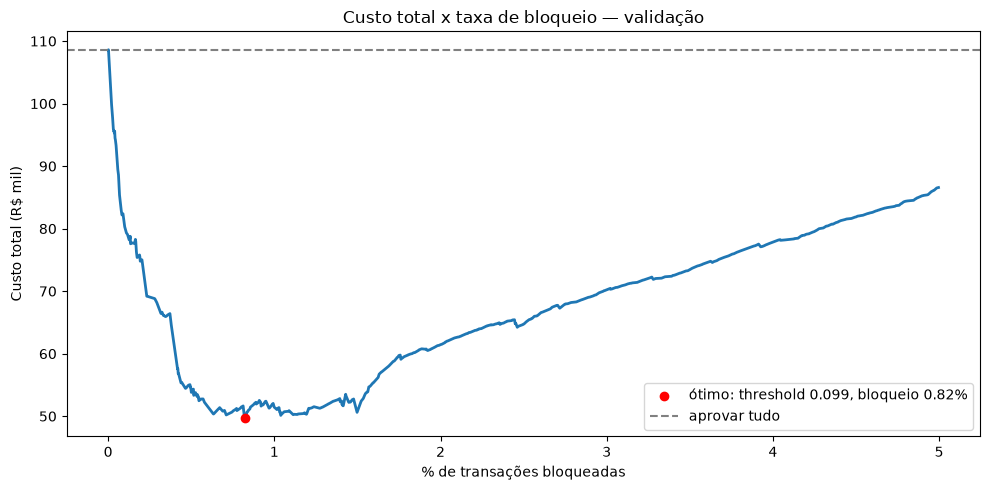

In [26]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))
plot_curve = curve_valid[curve_valid["block_rate"] <= 0.05]
ax.plot(plot_curve["block_rate"] * 100, plot_curve["total_cost"] / 1e3, linewidth=2)
best_row = curve_valid.loc[curve_valid["total_cost"].idxmin()]
ax.scatter(best_row["block_rate"] * 100, best_row["total_cost"] / 1e3, color="red", zorder=3,
           label=f"ótimo: threshold {best_threshold:.3f}, bloqueio {best_row['block_rate']:.2%}")
ax.axhline(curve_valid["total_cost"].iloc[0] / 1e3, color="gray", linestyle="--", label="aprovar tudo")
ax.set_xlabel("% de transações bloqueadas")
ax.set_ylabel("Custo total (R$ mil)")
ax.set_title("Custo total x taxa de bloqueio — validação")
ax.legend()
plt.tight_layout()
plt.show()

## Avaliação no teste

Comparação com:
* **aprovar tudo** (sem modelo)
* **regra de valor**: bloquear amount > 200 (política simples avaliada no notebook 1)

In [27]:
policies = {
    "aprovar tudo": np.zeros(len(test), dtype=bool),
    "regra amount > 200": test["amount"].gt(200).to_numpy(),
    f"modelo 4 (threshold {best_threshold:.3f})": score_test_4 >= best_threshold,
}

policy_results_test = pd.DataFrame(
    {name: decision_pnl(test[target], blocked, test["amount"], **pnl_params)
     for name, blocked in policies.items()}
).T

policy_results_test

,n_txns,block_rate,tp,fp,fn,tn,recall,precision,fraud_amount_blocked_pct,fn_cost,fp_cost,total_cost,savings_vs_approve_all
aprovar tudo,51557.0,0.000000,0.0,0.0,171.0,51386.0,0.000000,0.000000,0.000000,87646.70,0.000,87646.700,0.000
regra amount > 200,51557.0,0.048180,119.0,2365.0,52.0,49021.0,0.695906,0.047907,0.985207,2038.59,113942.594,115981.184,-28334.484
modelo 4 (threshold 0.099),51557.0,0.007235,61.0,312.0,110.0,51074.0,0.356725,0.163539,0.568617,38352.76,25367.162,63719.922,23926.778


## Sensibilidade ao custo de análise manual

Para cada custo, o threshold é reotimizado na validação e aplicado no teste.

In [28]:
sensitivity = []
for review_cost in [0.0, 2.0, 5.0, 10.0, 20.0]:
    params = {**pnl_params, "review_cost": review_cost}
    curve = threshold_cost_curve(valid[target], score_valid_4, valid["amount"], **params)
    threshold = optimal_threshold(curve)
    result = decision_pnl(test[target], score_test_4 >= threshold, test["amount"], **params)
    sensitivity.append({"review_cost": review_cost, "threshold": threshold, **result})

pd.DataFrame(sensitivity).set_index("review_cost")[
    ["threshold", "block_rate", "recall", "precision", "fn_cost", "fp_cost",
     "total_cost", "savings_vs_approve_all"]
]

,threshold,block_rate,recall,precision,fn_cost,fp_cost,total_cost,savings_vs_approve_all
review_cost,,,,,,,,
0.0,0.044865,0.013500,0.526316,0.129310,22303.82,39897.152,62200.972,25445.728
2.0,0.099235,0.007235,0.356725,0.163539,38352.76,24431.162,62783.922,24862.778
5.0,0.099235,0.007235,0.356725,0.163539,38352.76,25367.162,63719.922,23926.778
10.0,0.099235,0.007235,0.356725,0.163539,38352.76,26927.162,65279.922,22366.778
20.0,0.125605,0.004927,0.315789,0.212598,43005.88,21090.962,64096.842,23549.858
